# Baseline vs. frozen alert archive

This notebook is a part of the alert-archive verification notebooks:
1. **Baseline vs. frozen:** (⭐ you are here)
    - Just to make sure we're on track with the new alert-archive pipeline.
    - The baseline is a subset of the initial pq dump, so it is a subset of the frozen catalog.
2. **Replay vs frozen:**
    - With the "daily replays" added to the baseline, this version of the **working catalog** now spans the entire original pq dump.
    - This means it can properly be compared to the **frozen catalog**, which was originally built by that same dump.
    - Spoiler alert, we find them to be equivalent :)
3. **Daily ingest summary:**
    - A summary of the working catalog after running the daily ingest process on the **new** alerts.
    - Because we are now going beyond the frozen catalog, this notebook instead explores the partitioning, coverage, etc.

> [!NOTE]
> This was run from a brach, against `olivia/baseline @ db43161`

One-off comparison of the new **working catalog** built by the baseline job with the **frozen** catalog
that users and the nightly benchmarks use today. Written 2026-10-30, after Slurm job 42547515
(`scripts/baseline.sbatch` on `olivia/baseline` @ `db43161`: 30 min on one milano node,
16 Dask workers x 24 GiB, peak RSS ~129 GB, no worker restarts).

This is the second build. The first (job 42522881, kept as `baseline_vs_frozen_first_run_42522881.ipynb`)
also imported the dump's 5-digit-prefix chunks (`17005__*`, `17006__*`), which are exact copies of
alerts in 6-digit chunks, and used a 1 GiB byte threshold. This build skips them and uses 200k rows.

| | Path |
|---|---|
| Working (new) | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/working` |
| Frozen | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive` |
| Input dump | `/sdf/data/rubin/user/ncaplar/alert-parquet` (the 263 Jun 26 chunks with 6-digit prefixes) |

Sections:
1. Was every input alert imported?
2. Catalog properties side by side
3. Partitioning
4. Columns and schema
5. Which alerts differ between the two catalogs, and when they were observed
6. Spot check of values for alerts in both

In [1]:
from collections import Counter
from pathlib import Path

import hats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from alert_archive.baseline import baseline_chunks
from alert_archive.config import PathConfig
from alert_archive.daily.increment import consolidated_file_name, leaf_files
from alert_archive.state import PipelineState

paths = PathConfig()
WORKING = paths.working_dir
FROZEN = Path("/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive")
working, frozen = hats.read_hats(WORKING), hats.read_hats(FROZEN)


def data_files(catalog_dir):
    """Every data parquet file of a catalog, for flat (Npix=N.parquet) or leaf-directory layouts."""
    dataset = Path(catalog_dir) / "dataset"
    return sorted(p for p in dataset.glob("Norder=*/Dir=*/**/*.parquet"))


def read_column(catalog_dir, column):
    """One column (dotted paths allowed for nested fields) from every file, as a flat arrow array."""
    field = column.partition(".")[2]
    chunks = []
    for path in data_files(catalog_dir):
        col = pq.read_table(path, columns=[column]).column(0).combine_chunks()
        if field and pa.types.is_struct(col.type):  # nested columns are struct-of-lists
            col = pc.struct_field(col, field)
        if pa.types.is_list(col.type) or pa.types.is_large_list(col.type):  # one diaSource per alert
            col = pc.list_flatten(col)
        chunks.append(col)
    return pa.concat_arrays(chunks)

## 1. Was every input alert imported?

Rows in the 263 input chunks (from their parquet footers) against the rows in the working catalog's files
and the row count the baseline logged in `ingested.jsonl`. All three should match exactly.

In [2]:
chunks = baseline_chunks(paths.dump_dir)
input_rows = sum(pq.read_metadata(c).num_rows for c in chunks)
catalog_rows = sum(pq.read_metadata(p).num_rows for p in data_files(WORKING))
(run,) = PipelineState(paths.state_dir).runs()

pd.DataFrame(
    {
        "count": [len(chunks), input_rows, catalog_rows, run.num_rows, working.catalog_info.total_rows],
    },
    index=[
        "input chunks",
        "rows in input chunks",
        "rows in working catalog files",
        "rows logged in ingested.jsonl",
        "hats_nrows in hats.properties",
    ],
).style.format("{:,}")

,count
input chunks,263
rows in input chunks,"10,772,712"
rows in working catalog files,"10,772,712"
rows logged in ingested.jsonl,"10,772,712"
hats_nrows in hats.properties,"10,772,712"


In [3]:
print(f"Logged run {run.run_id}: {len(run.chunks)} chunks, format IDs {run.schema_id_counts}, skipped {run.skipped}")
assert input_rows == catalog_rows == run.num_rows == working.catalog_info.total_rows
assert [c.name for c in chunks] == run.chunks

Logged run 20261031T014526Z: 263 chunks, format IDs {1100: 10772712}, skipped {}


## 2. Catalog properties side by side

From each catalog's `hats.properties`. The working catalog uses leaf directories (`npix_suffix = /`).
Both use at most ~200k rows per partition, but the working catalog holds only the Jun 26 alerts
(10.8M of the frozen catalog's 16.5M), so partitions won't line up exactly.

In [4]:
def props(cat):
    i = cat.catalog_info
    return {
        "catalog_name": i.catalog_name,
        "total_rows": f"{i.total_rows:,}",
        "partitions": len(cat.get_healpix_pixels()),
        "hats_max_rows": f"{i.hats_max_rows:,}",
        "hats_order (deepest)": i.hats_order,
        "moc_sky_fraction": i.moc_sky_fraction,
        "npix_suffix": i.npix_suffix,
        "skymap_order": i.skymap_order,
        "est. size on disk (GB)": round(int(i.extra_dict().get("hats_estsize", 0)) / 1e6, 1),
        "default columns": len(i.default_columns or []),
    }


pd.DataFrame({"working (new)": props(working), "frozen": props(frozen)})

,working (new),frozen
catalog_name,rubin_alert_archive,rubin_alert_archive
total_rows,"10,772,712","16,466,969"
partitions,136,227
hats_max_rows,"200,000","198,913"
hats_order (deepest),7,7
moc_sky_fraction,0.31485,0.19786
npix_suffix,/,.parquet
skymap_order,10,10
est. size on disk (GB),0.0,0.0
default columns,25,25


In [5]:
print("Same default columns:", working.catalog_info.default_columns == frozen.catalog_info.default_columns)
files = leaf_files(WORKING)
print("Every working pixel holds exactly one consolidated Npix=<pixel>.parquet:",
      all([f.name for f in fs] == [consolidated_file_name(px)] for px, fs in files.items()))

Same default columns: True
Every working pixel holds exactly one consolidated Npix=<pixel>.parquet: True


## 3. Partitioning

Rows per partition and partitions per HEALPix order. Both are capped near 200k rows; the frozen
catalog's layout was computed from more alerts, so its partitions are split differently.

In [6]:
def rows_per_partition(catalog_dir):
    rows = Counter()
    for p in data_files(catalog_dir):
        rows[hats.io.paths.get_healpix_from_path(p)] += pq.read_metadata(p).num_rows
    return pd.Series(rows)


rpp = {"working (new)": rows_per_partition(WORKING), "frozen": rows_per_partition(FROZEN)}
pd.DataFrame({k: v.describe(percentiles=[0.1, 0.5, 0.9]) for k, v in rpp.items()}).round(0).astype(int).T

,count,mean,std,min,10%,50%,90%,max
working (new),136,79211,47085,20,12662,76972,150670,195044
frozen,227,72542,46115,12,10227,68045,140019,198913


In [7]:
orders = pd.DataFrame(
    {k: Counter(px.order for px in v.index) for k, v in rpp.items()}
).fillna(0).astype(int).sort_index()
orders.index.name = "HEALPix order"
orders.T

HEALPix order,0,1,2,3,4,5,6,7
working (new),3,2,2,6,10,7,39,67
frozen,0,6,5,27,31,4,30,124


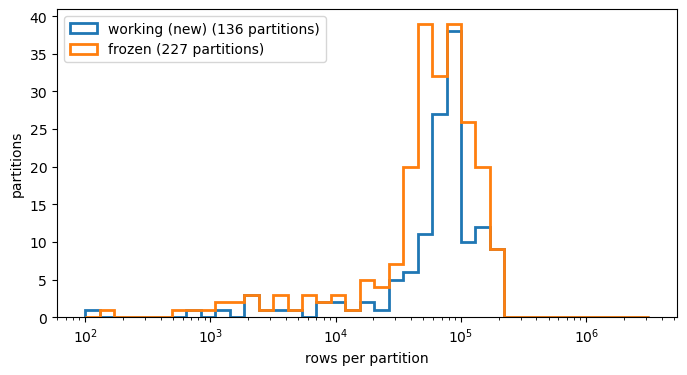

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(2, 6.5, 40)
for name, series in rpp.items():
    ax.hist(series.values, bins=bins, histtype="step", lw=2, label=f"{name} ({len(series)} partitions)")
ax.set_xscale("log")
ax.set_xlabel("rows per partition")
ax.set_ylabel("partitions")
ax.legend()
plt.show()

## 4. Columns and schema

Top-level columns, and the number of fields in each nested column. The working catalog is conformed to
alert format 1101 (four new `diaSource` fields, also in `prvDiaSources`), and adds `schemaId`.

In [9]:
ws, fs = pq.read_schema(WORKING / "dataset" / "_common_metadata"), pq.read_schema(FROZEN / "dataset" / "_common_metadata")


def n_fields(schema, name):
    t = schema.field(name).type
    return t.num_fields if pa.types.is_struct(t) else "-"


names = list(dict.fromkeys(ws.names + fs.names))
pd.DataFrame(
    {
        "in working": [n in ws.names for n in names],
        "in frozen": [n in fs.names for n in names],
        "fields (working)": [n_fields(ws, n) if n in ws.names else "" for n in names],
        "fields (frozen)": [n_fields(fs, n) if n in fs.names else "" for n in names],
    },
    index=names,
)

,in working,in frozen,fields (working),fields (frozen)
_healpix_29,True,True,-,-
ra,True,True,-,-
dec,True,True,-,-
diaSourceId,True,True,-,-
schemaId,True,False,-,
observation_reason,True,True,-,-
target_name,True,True,-,-
diaSource,True,True,102,98
prvDiaSources,True,True,102,98
prvDiaForcedSources,True,True,14,14


In [10]:
for name in ["diaSource", "prvDiaSources", "prvDiaForcedSources", "diaObject"]:
    w = {f.name for f in ws.field(name).type}
    f = {f.name for f in fs.field(name).type}
    print(f"{name:20s} only in working: {sorted(w - f)}   only in frozen: {sorted(f - w)}")

diaSource            only in working: ['exposureTime', 'reliabilityVersion', 'trailAlgorithm', 'trail_flag']   only in frozen: []
prvDiaSources        only in working: ['exposureTime', 'reliabilityVersion', 'trailAlgorithm', 'trail_flag']   only in frozen: []
prvDiaForcedSources  only in working: []   only in frozen: []
diaObject            only in working: []   only in frozen: []


## 5. Which alerts differ, and when were they observed?

The frozen catalog has more rows (it includes the Jul 13/21/31 alerts the replay will add). Compare the two by `diaSourceId` (one alert per row in both), then look
at when the alerts found in only one catalog were observed (`diaSource.midpointMjdTai`, as integer MJD).

In [11]:
ids = {name: read_column(d, "diaSourceId").to_numpy() for name, d in [("working", WORKING), ("frozen", FROZEN)]}
for name, a in ids.items():
    print(f"{name:8s} rows {len(a):>12,}   unique diaSourceId {len(np.unique(a)):>12,}")

both = np.intersect1d(ids["working"], ids["frozen"])
only_working = np.setdiff1d(ids["working"], ids["frozen"])
only_frozen = np.setdiff1d(ids["frozen"], ids["working"])
pd.Series(
    {"in both": len(both), "only in working (new)": len(only_working), "only in frozen": len(only_frozen)}
).map("{:,}".format).to_frame("alerts")

working  rows   10,772,712   unique diaSourceId   10,772,712
frozen   rows   16,466,969   unique diaSourceId   16,466,969


,alerts
in both,"10,772,712"
only in working (new),0
only in frozen,"5,694,257"


In [12]:
def night_counts(catalog_dir, id_array, wanted):
    """Alerts per integer MJD, among those whose diaSourceId is in ``wanted``."""
    mjd = read_column(catalog_dir, "diaSource.midpointMjdTai").to_numpy()
    keep = np.isin(id_array, wanted)
    return pd.Series(np.floor(mjd[keep]).astype(int)).value_counts().sort_index()


nights = pd.DataFrame(
    {
        "in both": night_counts(FROZEN, ids["frozen"], both),
        "only in frozen": night_counts(FROZEN, ids["frozen"], only_frozen),
        "only in working": night_counts(WORKING, ids["working"], only_working),
    }
).fillna(0).astype(int)
nights.index.name = "MJD"
print("Observation dates, as MJD ranges:")
for col in nights:
    nz = nights.index[nights[col] > 0]
    print(f"  {col:16s} {nz.min() if len(nz) else '-'} .. {nz.max() if len(nz) else '-'}")

Observation dates, as MJD ranges:
  in both          61088 .. 61217
  only in frozen   60973 .. 61235
  only in working  - .. -


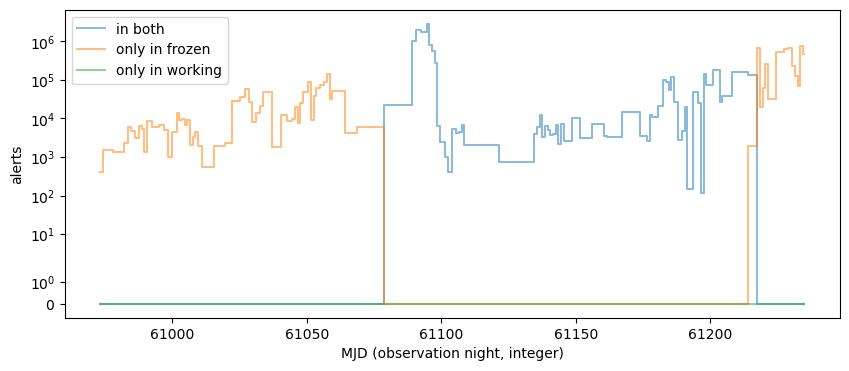

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for col in nights:
    ax.step(nights.index, nights[col], where="mid", label=col, alpha=0.5)
ax.set_xlabel("MJD (observation night, integer)")
ax.set_ylabel("alerts")
ax.set_yscale("symlog")
ax.legend()
plt.show()

In [14]:
# Nights with any alerts only in one catalog
nights[(nights["only in frozen"] > 0) | (nights["only in working"] > 0)]

,in both,only in frozen,only in working
MJD,,,
60973,0,414,0
60975,0,1479,0
...,...,...,...
61234,0,744559,0
61235,0,473344,0


## 6. Spot check: same alert, same values?

For a random sample of alerts in both catalogs, compare a few fields. Values should be identical
(the import only reshapes and adds columns; it doesn't recompute anything).

In [15]:
rng = np.random.default_rng(0)
sample = set(rng.choice(both, size=min(2000, len(both)), replace=False).tolist())
fields = ["ra", "dec", "diaSource.psfFlux", "diaSource.midpointMjdTai", "diaSource.band", "diaObject.diaObjectId"]


def sample_values(catalog_dir):
    out = {}
    for f in ["diaSourceId", *fields]:
        out[f] = read_column(catalog_dir, f).to_numpy(zero_copy_only=False)
    df = pd.DataFrame(out)
    # Keep one row per alert, in case a catalog holds the same diaSourceId twice (see section 5).
    return df[df["diaSourceId"].isin(sample)].drop_duplicates("diaSourceId").set_index("diaSourceId")


merged = sample_values(WORKING).join(sample_values(FROZEN), how="inner", lsuffix=" (working)", rsuffix=" (frozen)")
equal = {}
for f in fields:
    w, fr = merged[f"{f} (working)"], merged[f"{f} (frozen)"]
    equal[f] = bool(((w == fr) | (w.isna() & fr.isna())).all())

# Solar-system alerts have no diaObject: frozen stores a placeholder 0, working stores null.
w, fr = merged["diaObject.diaObjectId (working)"], merged["diaObject.diaObjectId (frozen)"]
null_vs_zero = w.isna() & (fr == 0)
equal["diaObject.diaObjectId (0 = null)"] = bool(((w == fr) | (w.isna() & fr.isna()) | null_vs_zero).all())
print(
    f"diaObject.diaObjectId: {null_vs_zero.sum()} sampled alerts are null in working and 0 in frozen "
    f"(solar-system alerts). Counting those as equal, the column "
    f"{'matches' if equal['diaObject.diaObjectId (0 = null)'] else 'still differs'}."
)
pd.Series(equal, name=f"identical across {len(merged)} sampled alerts").to_frame()


diaObject.diaObjectId: 122 sampled alerts are null in working and 0 in frozen (solar-system alerts). Counting those as equal, the column matches.


,identical across 2000 sampled alerts
ra,True
dec,True
diaSource.psfFlux,True
diaSource.midpointMjdTai,True
diaSource.band,True
diaObject.diaObjectId,False
diaObject.diaObjectId (0 = null),True


## Takeaways

- **The baseline is complete and has no duplicates.** 263 chunks, 10,772,712 alerts, all format 1100, and
  10,772,712 unique `diaSourceId`s. Input, files, log and `hats.properties` all agree.
- **Every working alert is in the frozen catalog** (0 only in working). The 5,694,257 only in frozen are
  exactly the Jul 13 + Jul 21 + Jul 31 dump alerts (4,051,289 + 473,344 + 1,169,624), which the replay will add.
  After the replay, the two catalogs should hold the same alerts.
- **Values match** for sampled alerts, except `diaObject.diaObjectId`: frozen has a placeholder 0 for
  solar-system alerts, working has null (kept on purpose).
- **Schema:** working adds the four 1101 fields to `diaSource`/`prvDiaSources`, and `schemaId`.
- **Partitions are now comparable:** 136 vs 227, median 77k vs 68k rows, both capped near 200k.
  Fewer partitions because the working catalog has fewer alerts so far. `moc_sky_fraction` is higher
  because it's computed from partition coverage, and a few big order-0 partitions cover sky the alerts don't.
